# La escalera de liquidez, la posición neta de liquidez y el período de supervivencia

**Pregunta:** ¿En qué día se queda sin liquidez el banco que quebró en marzo de 2023 bajo la fuga adversa del BCE, si su escalera contractual dice que solo está corto el primer día?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el tema 01 (instalar el motor y abrir un artefacto)
- **Tiempo de lectura:** unos 30 minutos

## Objetivos

Al terminar este notebook puedes:

- leer la escalera contractual de vencimientos de un balance y decir por qué sus brechas no dicen cuándo a un banco se le acaba la liquidez;
- enunciar la posición neta de liquidez `NLP(t)` y el período de supervivencia, y calcular ambos con el motor sobre el documento versionado del caso C16;
- explicar el efecto acantilado y por qué es un diagnóstico y no un límite;
- leer en dos figuras el día de supervivencia, el margen delgado que lo decide y la ventana del acantilado.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son el caso C16 de Contraste: el balance del banco que quebró el 2023-03-10, construido con los reportes de llamada de la FDIC hasta el 2022-12-31 (agregados públicos, clase de licencia `mirror-allowed`). Los agregados son reales, el **comportamiento y los depósitos son sintéticos**: el caso no representa al banco ni certifica ningún modelo.

- **Archivo que se lee:** `data/derived/C16/list-adverse.json`, la variante que corre las salidas del escenario Adverso de LiST 2019 del BCE en los seis meses posteriores al 2022-12-31 (125 días relevantes).
- **Unidades:** el dinero en miles de USD, los días contados desde 1 (el día 1 es el primer día relevante después de la fecha de valoración).
- Las claves de la escalera que se usan aquí son `outputs.contractual_ladder`, `outputs.path.ladder` (las series diarias) y `outputs.path.survival`.

La celda siguiente carga el documento e imprime qué versión del motor lo calculó, junto a la instalada.

In [2]:
# Cargar el documento versionado LiST Adverso del caso C16 (el notebook está tres carpetas bajo la raíz)
ROOT = Path("../../..").resolve()
path = ROOT / "data" / "derived" / "C16" / "list-adverse.json"
document = json.loads(path.read_text(encoding="utf-8"))
out = document["outputs"]

print("calculado con riskvalidation", document["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("fecha de valoración:", out["valuation_date"], "| moneda:", out["currency"])
print(out["bank"]["notice"]["es"])

calculado con riskvalidation 1.0.1 | instalado 1.0.1
fecha de valoración: 2022-12-31 | moneda: USD
Agregados reales del reporte de llamada FDIC usados solo como agregados públicos, con comportamiento y depósitos sintéticos: el caso no representa al banco ni certifica ningún modelo.


## Método

La escalera de liquidez de la prueba de tensión de liquidez (LiST) de 2019 del Banco Central Europeo tiene cuatro piezas, cada una una función de `riskvalidation.liquidity.ladder` (BCE, 2019, nota metodológica y anexo de resultados, sección E.1 del dosier de investigación). Las corremos una por una sobre el documento versionado.

### Paso 1: las brechas contractuales

Una escalera contractual pone cada flujo en el tramo de su vencimiento contractual. Con las entradas $I_b$ y las salidas $O_b$ del tramo $b$, la brecha y la brecha acumulada son (la herramienta de descalce de vencimientos contractuales del Marco de Basilea, SRP50):

$$\mathrm{gap}_b = I_b - O_b, \qquad \mathrm{cumulative\ gap}_b = \sum_{k \le b} \mathrm{gap}_k$$

La celda siguiente lee los siete tramos del documento, llama a `contractual_gaps` e imprime la escalera en miles de millones de USD.

In [3]:
# Los siete tramos contractuales del documento, y la brecha y la brecha acumulada del motor
from riskvalidation.liquidity.ladder import contractual_gaps

buckets = out["contractual_ladder"]["buckets"]
inflows = np.array([b["inflows"] for b in buckets])
outflows = np.array([b["outflows"] for b in buckets])
gap, cumulative_gap = contractual_gaps(inflows, outflows)

header = f"{'desde día':>9s}{'hasta día':>10s}{'entradas':>10s}{'salidas':>10s}{'brecha':>9s}{'acumulada':>11s}"
print(header, "  (miles de millones de USD)")
for b, g, c in zip(buckets, gap, cumulative_gap):
    end = "-" if b["to_day"] is None else str(b["to_day"])
    row = f"{b['from_day']:9d}{end:>10s}{b['inflows'] / 1e6:10.2f}{b['outflows'] / 1e6:10.2f}"
    print(row + f"{g / 1e6:9.2f}{c / 1e6:11.2f}")

desde día hasta día  entradas   salidas   brecha  acumulada   (miles de millones de USD)
        0         1     92.90    174.48   -81.58     -81.58
        1         7     83.00      0.31    82.69       1.10
        7        30     94.27      1.20    93.07      94.18
       30        90    118.80      3.12   115.68     209.86
       90       180     80.07      3.87    76.20     286.06
      180       365     81.18      7.95    73.22     359.28
      365         -    128.55      0.01   128.54     487.82


La celda siguiente dibuja la brecha acumulada de cada tramo, en rojo donde el banco está corto y en azul donde está largo.

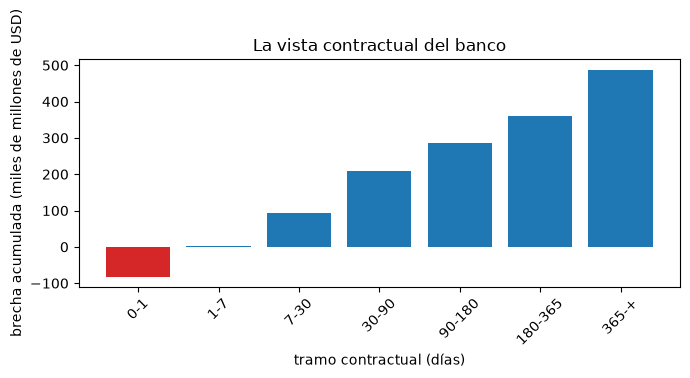

In [4]:
# Dibujar la brecha contractual acumulada por tramo: rojo donde el banco está corto, azul donde está largo
labels = [f"{b['from_day']}-{'+' if b['to_day'] is None else b['to_day']}" for b in buckets]
colors = ["tab:red" if c < 0 else "tab:blue" for c in cumulative_gap]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(range(len(buckets)), cumulative_gap / 1e6, color=colors)
ax.set_xticks(range(len(buckets)))
ax.set_xticklabels(labels, rotation=45)
ax.set_xlabel("tramo contractual (días)")
ax.set_ylabel("brecha acumulada (miles de millones de USD)")
ax.set_title("La vista contractual del banco")
fig.tight_layout()
plt.show()

La figura muestra la vista contractual. El primer tramo, del día 0 al día 1, es con mucho negativo (-81,58 mil millones de USD): los depósitos a la vista no tienen vencimiento contractual y quedan en el primer tramo, mientras los activos del balance vencen después. Toda brecha acumulada posterior es positiva y llega a 359,28 mil millones en el tramo del último año. La vista contractual dice que el banco está corto solo el primer día y luego holgado, justo lo que una corrida no respeta. Lo que la figura no puede mostrar es la velocidad con que los depósitos salen de verdad, y eso necesita la escalera conductual.

### Paso 2: la posición neta de liquidez

La escalera conductual reemplaza los flujos contractuales por flujos bajo tensión. Con la capacidad de contrapeso $\mathrm{CBC}(t)$ (el stock de activos líquidos no gravados, después de recortes, que puede volverse efectivo hasta el día $t$) y las salidas $O(s)$ y entradas $I(s)$ bajo tensión del día $s$ (BCE, 2019, definiciones de LiST):

$$\mathrm{NLP}(t) = \mathrm{CBC}(t) - \sum_{s \le t} \bigl(O(s) - I(s)\bigr)$$

La celda siguiente lee las tres series diarias del documento (125 días), llama a `net_liquidity_position` e imprime siete días de la identidad.

In [5]:
# La CBC diaria, las salidas y las entradas del documento, y la NLP del motor
from riskvalidation.liquidity.ladder import net_liquidity_position

ladder = out["path"]["ladder"]
cbc = np.array(ladder["cbc_total"])
daily_outflows = np.array(ladder["total_outflows"])
daily_inflows = np.array(ladder["total_inflows"])
nlp = net_liquidity_position(cbc, daily_outflows, daily_inflows)
net_outflow = np.cumsum(daily_outflows - daily_inflows)

print("días en la escalera:", len(nlp))
for day in (1, 2, 3, 30, 61, 62, 125):
    i = day - 1
    flows = f"CBC {cbc[i] / 1e6:6.2f} | salida neta acumulada {net_outflow[i] / 1e6:7.2f}"
    print(f"día {day:3d} | {flows} | NLP {nlp[i] / 1e6:7.2f}")

días en la escalera: 125
día   1 | CBC  35.84 | salida neta acumulada   14.86 | NLP   20.98
día   2 | CBC  57.34 | salida neta acumulada   15.99 | NLP   41.35
día   3 | CBC  71.67 | salida neta acumulada   17.12 | NLP   54.55
día  30 | CBC  71.67 | salida neta acumulada   44.96 | NLP   26.71
día  61 | CBC  71.67 | salida neta acumulada   71.56 | NLP    0.11
día  62 | CBC  71.67 | salida neta acumulada   72.33 | NLP   -0.66
día 125 | CBC  71.67 | salida neta acumulada  112.64 | NLP  -40.97


La identidad se ve en la tabla: la NLP de un día es el CBC de ese día menos la salida neta acumulada. El CBC crece en los tres primeros días (el calendario de monetización es una convención declarada: 50%, 80% y 100% del valor de liquidez de los activos en los días 1, 2 y 3) y luego queda plano, mientras la salida neta acumulada sigue subiendo con la fuga bajo tensión de cada día. Hacia el día 62 las dos líneas se cruzan; la figura del final de este notebook las dibuja.

### Paso 3: el período de supervivencia

El período de supervivencia es el primer día en que la NLP se vuelve negativa (BCE, 2019):

$$\mathrm{SP} = \min\{\, t : \mathrm{NLP}(t) < 0 \,\}$$

Una NLP igual a cero no es negativa. Una posición que nunca se vuelve negativa no tiene día de supervivencia: el motor devuelve "sobrevive el horizonte" con el horizonte, nunca un número. La celda siguiente llama a `survival_period` y a `minimum_nlp`.

In [6]:
# El período de supervivencia y la NLP mínima, desde el motor
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

result = survival_period(nlp)
low, low_day = minimum_nlp(nlp)

print("sobrevive el horizonte:", "sí" if result.survives else "no")
print("día de supervivencia:", result.day, "| horizonte:", result.horizon)
print("NLP mínima (miles de millones de USD) y su día:", round(low / 1e6, 2), low_day)

sobrevive el horizonte: no
día de supervivencia: 62 | horizonte: 125
NLP mínima (miles de millones de USD) y su día: -40.97 125


### Paso 4: el efecto acantilado

El efecto acantilado compara la NLP en dos días, a un mes y a un mes y una semana del inicio, como proporción de los activos totales $\mathrm{TA}$ (BCE, 2019):

$$\mathrm{cliff} = \frac{\mathrm{NLP}(35) - \mathrm{NLP}(30)}{\mathrm{TA}}$$

Es un diagnóstico de la optimización de la ventana del LCR: un banco que arregla sus flujos para que el coeficiente de cobertura de liquidez a 30 días se vea bien puede aún caer fuerte unos días después. La nota de LiST no dice si los días son corridos o relevantes; el motor los toma como el parámetro nombrado `cliff_days` y el documento cuenta días relevantes (una convención declarada). La celda siguiente llama a `cliff_effect` con los activos totales del balance.

In [7]:
# El efecto acantilado entre el día 30 y el día 35 como proporción de los activos totales, desde el motor
from riskvalidation.liquidity.ladder import cliff_effect

total_assets = out["balance_sheet"]["total_assets"]
cliff = cliff_effect(nlp, total_assets, near=30, far=35)

print("activos totales (miles de millones de USD):", round(total_assets / 1e6, 2))
print("NLP(30) =", round(nlp[29] / 1e6, 3), "| NLP(35) =", round(nlp[34] / 1e6, 3))
print("cambio de la NLP (miles de millones de USD):", round((nlp[34] - nlp[29]) / 1e6, 3))
print("efecto acantilado:", round(cliff, 6))

activos totales (miles de millones de USD): 209.03
NLP(30) = 26.713 | NLP(35) = 22.063
cambio de la NLP (miles de millones de USD): -4.65
efecto acantilado: -0.022246


La última celda dibuja la vista conductual. El CBC (verde), la salida neta acumulada (naranja) y su diferencia, la NLP (azul), a lo largo de los 125 días, con el día de supervivencia marcado y la ventana del acantilado sombreada.

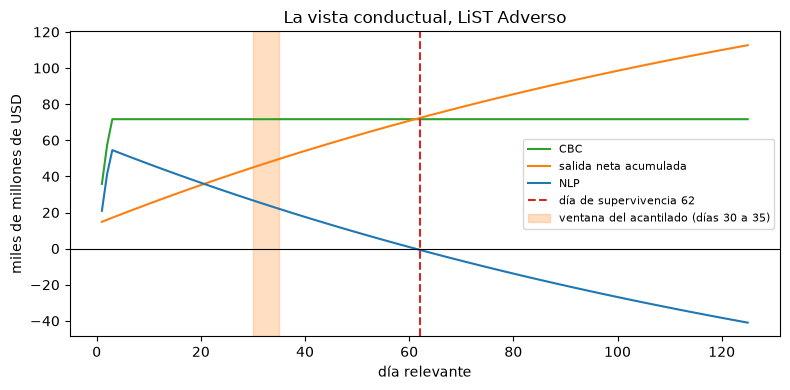

In [8]:
# Dibujar la CBC, la salida neta acumulada y su diferencia, la NLP, con el día de supervivencia y el acantilado
days = np.arange(1, len(nlp) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(days, cbc / 1e6, color="tab:green", label="CBC")
ax.plot(days, net_outflow / 1e6, color="tab:orange", label="salida neta acumulada")
ax.plot(days, nlp / 1e6, color="tab:blue", label="NLP")
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(result.day, color="tab:red", linestyle="--", label=f"día de supervivencia {result.day}")
ax.axvspan(30, 35, color="tab:orange", alpha=0.25, label="ventana del acantilado (días 30 a 35)")
ax.set_xlabel("día relevante")
ax.set_ylabel("miles de millones de USD")
ax.set_title("La vista conductual, LiST Adverso")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La vista conductual tiene una forma que la contractual no puede tener. El CBC sube a 71,67 mil millones de USD en tres días y luego queda plano, la salida neta acumulada sube de manera sostenida, y la NLP, la diferencia entre ambos, alcanza su máximo de 54,55 mil millones el día 3 y se desliza hasta cero hacia el día 62, la línea roja. La pendiente es suave, así que el cruce es sensible: el día 61 la posición todavía está 0,11 mil millones sobre cero. La banda naranja es la ventana del acantilado, donde la NLP pierde 4,65 mil millones en cinco días. La figura no dice por qué la salida lleva este ritmo; eso es la tasa de fuga del notebook 02.

## Resultados

**Respuesta:** El banco se queda sin liquidez el día 62 de los 125 días relevantes de la fuga LiST Adversa: la NLP es 0,11 mil millones de USD el día 61, -0,66 mil millones el día 62 y cae a su mínimo de -40,97 mil millones el día 125. La escalera contractual no puede decir esto: su brecha acumulada es negativa solo en el primer tramo (-81,58 mil millones) y positiva después.

- **Vista contractual.** La brecha acumulada es negativa solo en el primer tramo (-81,58 mil millones de USD: los depósitos a la vista, puestos en el día 0 a 1) y positiva en todos los siguientes, hasta 487,82 mil millones en el último. La vista contractual no puede decir cuándo le falta liquidez al banco.
- **Posición neta de liquidez.** La NLP parte en 20,98 mil millones el día 1 y sube a 54,55 el día 3 a medida que se monetiza el CBC (71,67 mil millones en total); luego cae con la fuga acumulada: 26,71 el día 30, 0,11 el día 61, -0,66 el día 62 y -40,97 el día 125, su mínimo.
- **Período de supervivencia.** El período de supervivencia es el día 62 de un horizonte de 125. El margen es delgado donde importa: el día 61 la NLP está apenas 0,11 mil millones sobre cero, así que un cambio pequeño en una tasa de fuga o en el CBC mueve el día. El número es una propiedad del comportamiento sintético (el mapeo de depósitos y el calendario de monetización son convenciones), no un pronóstico para el banco.
- **Efecto acantilado.** El efecto acantilado es -0,022246: la NLP cae 4,65 mil millones entre el día 30 y el día 35, el 2,2% de los 209,03 mil millones de activos totales. La prueba calificada del producto (ámbar bajo -1%, rojo bajo -3%) es una convención del producto, porque la nota de LiST no define ningún límite.

Lo que este notebook no muestra: de dónde salen las tasas de fuga y el CBC (notebooks 02 y 03), cómo se componen los escenarios (notebook 04) o cómo se relaciona el LCR a 30 días con el período de supervivencia (notebook 05). El banco es real solo en agregado: el día de supervivencia es una propiedad del comportamiento sintético, no del banco.

## Resumen

- Una escalera contractual da brechas por tramo de vencimiento; no puede decir cuándo se queda sin efectivo un banco con depósitos a la vista.
- La posición neta de liquidez es el CBC del día menos la salida neta acumulada bajo tensión; el período de supervivencia es el primer día en que es negativa, o "sobrevive el horizonte".
- El efecto acantilado es un diagnóstico de la forma de la posición, en proporción de los activos totales, no un límite.
- Sobre el comportamiento sintético del caso C16 el período de supervivencia es el día 62, con un margen de 0,11 mil millones de USD el día anterior.

**Qué probar a continuación.** Cambia la ventana del acantilado (`near=20`, `far=25`) y mira cómo se mueve el diagnóstico; luego sigue con el notebook 02, donde se derivan las tasas de fuga detrás de la NLP.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf